本 notebook 是 [M01.4 计算机系统基础](../notes/04-computer-systems.qmd) 的实例讲解，用可运行的代码观察讲义中的几个系统层面的结论：

1. 本机的硬件参数：核数、缓存行、缓存大小；
2. 缓存局部性：步长访问与随机访问；
3. 浮点数的比特布局、机器精度与相邻浮点数的间距；
4. 灾难性抵消：同一个量的两种算法；
5. 累加误差：float32、float64、Kahan 补偿求和与 `math.fsum`；
6. GIL：线程与进程在 CPU 密集和等待型任务上的差别；
7. I/O：小块写入的系统调用开销，文本与二进制格式。

NumPy 内存布局、strides、向量化和性能分析工具在 [M01.5 高性能科学 Python](../notes/05-high-performance-python.qmd) 中系统讲解，这里只把 NumPy 当作“能精确控制访问模式的数组”。

**运行方式**：在 VS Code 中打开本文件，选择仓库 `.venv` 的 Python 内核，从上到下运行，合计约半分钟到一分钟。改动代码后可用 `make nb M=01` 重新执行并保存输出。所有计时都依赖机器和当时的负载，下面只用**相对量**（倍数）下结论。

In [1]:
import math
import os
import platform
import struct
import subprocess
import sys
import tempfile
import time
from concurrent.futures import ProcessPoolExecutor, ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from semiai.plotting import BLUE, GRAY, MUTED, ORANGE, use_style

use_style()
rng = np.random.default_rng(0)


def best_time(fn, repeat: int = 5) -> float:
    """多次运行取最短耗时（秒）。最短值受后台干扰最小。"""
    times = []
    for _ in range(repeat):
        t0 = time.perf_counter()
        fn()
        times.append(time.perf_counter() - t0)
    return min(times)

## 1. 本机的硬件参数

先看这台机器。缓存行（cache line）是 CPU 与内存之间搬运数据的最小单位；后面所有局部性实验的“台阶”都取决于它和各级缓存的大小。macOS 用 `sysctl` 查询，Linux 可以读 `/sys/devices/system/cpu/cpu0/cache/`，或用 `lscpu`。

In [2]:
def sysctl(name: str) -> str:
    try:
        out = subprocess.run(["sysctl", "-n", name], capture_output=True, text=True, timeout=5)
        return out.stdout.strip() or "—"
    except (OSError, subprocess.SubprocessError):
        return "—"


info = {
    "平台": f"{platform.system()} {platform.machine()}",
    "Python": platform.python_version(),
    "逻辑核数 os.cpu_count()": os.cpu_count(),
    "GIL 是否启用": (
        sys._is_gil_enabled() if hasattr(sys, "_is_gil_enabled") else "是（非 free-threaded 构建）"
    ),
}
if platform.system() == "Darwin":
    info |= {
        "缓存行（字节）": sysctl("hw.cachelinesize"),
        "L1 数据缓存（字节）": sysctl("hw.l1dcachesize"),
        "L2 缓存（字节）": sysctl("hw.l2cachesize"),
        "性能核簇 L2（字节）": sysctl("hw.perflevel0.l2cachesize"),
    }
pd.Series(info, name="值").to_frame()

,值
平台,Darwin arm64
Python,3.12.13
逻辑核数 os.cpu_count(),10
GIL 是否启用,是（非 free-threaded 构建）
缓存行（字节）,128
L1 数据缓存（字节）,65536
L2 缓存（字节）,4194304
性能核簇 L2（字节）,16777216


读法：记下缓存行大小（Apple Silicon 是 128 字节，多数 x86 是 64 字节）和核数，第 2、6 节会用到。本机 Python 是标准构建，GIL 启用；Python 3.13 起有可选的 free-threaded 构建，那时第 6 节的结论会变。

## 2. 缓存局部性：步长与随机访问

**实验 A：固定读取的元素个数，改变步长。** 从一个大数组里每隔 `stride` 个 float64 取一个，一共取 25 万个，求和（最大步长时数组约 256 MB）。读取的数据量不变，变的只是相邻两次访问在内存中隔多远。步长为 1 时，一个 128 字节的缓存行能服务 16 次读取；步长达到 16（= 128 字节）以后，每次读取都要搬一整行新的缓存行。

In [3]:
n_read = 250_000
strides = [1, 2, 4, 8, 16, 32, 64, 128]
base = np.ones(n_read * max(strides))  # 约 256 MB
rows = []
for s in strides:
    view = base[::s][:n_read]  # 不拷贝的跨步视图
    t = best_time(lambda v=view: v.sum(), repeat=7)
    rows.append({"步长（元素）": s, "步长（字节）": 8 * s, "每元素耗时（ns）": 1e9 * t / n_read})
stride_df = pd.DataFrame(rows).set_index("步长（元素）")
per_elem = stride_df["每元素耗时（ns）"]
stride_df["相对步长 1 的倍数"] = (per_elem / per_elem.iloc[0]).round(1)
stride_df.round(2)

,步长（字节）,每元素耗时（ns）,相对步长 1 的倍数
步长（元素）,,,
1,8,0.10,1.0
2,16,0.15,1.4
4,32,0.24,2.3
8,64,0.57,5.4
16,128,1.93,18.5
32,256,2.46,23.5
64,512,2.66,25.4
128,1024,3.09,29.6


**实验 B：同样的元素，顺序访问与随机访问。** 用一个整数索引数组从 `src` 中取出全部元素（gather）。顺序索引与打乱后的索引读到的是同一批数，只是顺序不同。改变数组大小，看它跨过各级缓存时发生什么。

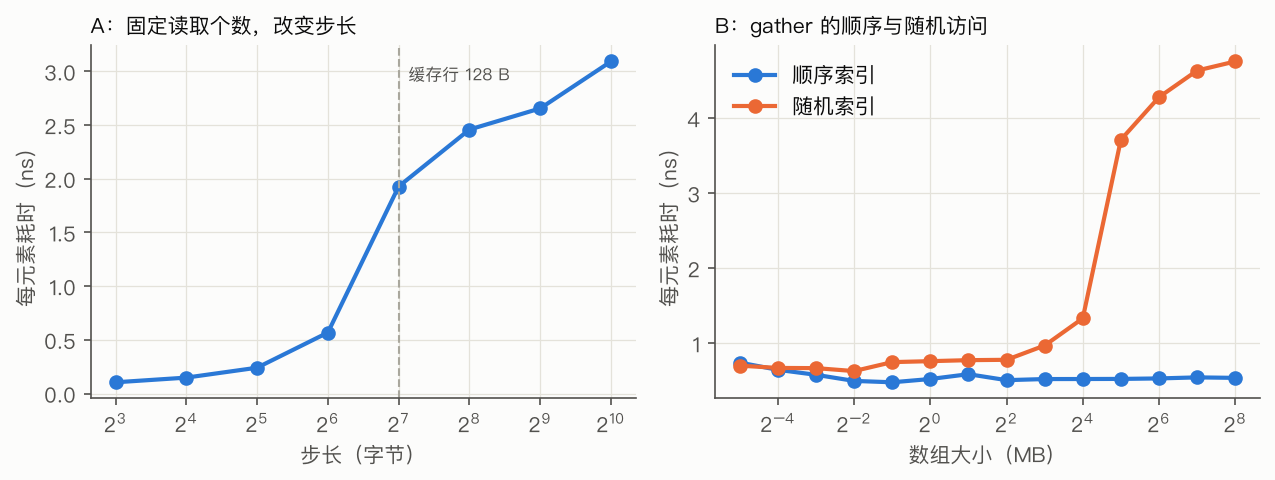

,数据量（MB）,顺序 ns/元素,随机 ns/元素,随机/顺序
元素数,,,,
4096,0.03,0.74,0.70,0.95
65536,0.50,0.48,0.75,1.56
1048576,8.00,0.52,0.97,1.85
8388608,64.00,0.53,4.28,8.05
33554432,256.00,0.54,4.76,8.83


In [4]:
sizes = 2 ** np.arange(12, 26, 1)  # 4K 到 32M 个 float64，即 32 KB 到 256 MB
rows = []
for n in sizes:
    src = rng.random(n)
    seq_idx = np.arange(n)
    rnd_idx = rng.permutation(n)
    rep = 5 if n <= 2**22 else 3
    t_seq = best_time(lambda s=src, i=seq_idx: s[i].sum(), repeat=rep)
    t_rnd = best_time(lambda s=src, i=rnd_idx: s[i].sum(), repeat=rep)
    rows.append({"元素数": n, "数据量（MB）": n * 8 / 2**20,
                 "顺序 ns/元素": 1e9 * t_seq / n, "随机 ns/元素": 1e9 * t_rnd / n})
gather_df = pd.DataFrame(rows)
gather_df["随机/顺序"] = gather_df["随机 ns/元素"] / gather_df["顺序 ns/元素"]

fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.3))
axes[0].plot(stride_df.index * 8, stride_df["每元素耗时（ns）"], "o-", color=BLUE)
axes[0].set_xscale("log", base=2)
axes[0].set_xlabel("步长（字节）")
axes[0].set_ylabel("每元素耗时（ns）")
axes[0].set_title("A：固定读取个数，改变步长", loc="left", fontsize=10)
line = sysctl("hw.cachelinesize") if platform.system() == "Darwin" else "—"
if line.isdigit():
    axes[0].axvline(int(line), color=GRAY, ls="--", lw=1)
    axes[0].text(int(line) * 1.1, axes[0].get_ylim()[1] * 0.9, f"缓存行 {line} B",
                 color=MUTED, fontsize=8)
mb = gather_df["数据量（MB）"]
axes[1].plot(mb, gather_df["顺序 ns/元素"], "o-", color=BLUE, label="顺序索引")
axes[1].plot(mb, gather_df["随机 ns/元素"], "o-", color=ORANGE, label="随机索引")
axes[1].set_xscale("log", base=2)
axes[1].set_xlabel("数组大小（MB）")
axes[1].set_ylabel("每元素耗时（ns）")
axes[1].set_title("B：gather 的顺序与随机访问", loc="left", fontsize=10)
axes[1].legend()
fig.tight_layout()
plt.show()
gather_df.iloc[[0, 4, 8, 11, 13]].round(2).set_index("元素数")

读法：

- 实验 A：步长从 1 增加到缓存行大小附近时，每元素耗时成倍上升，之后趋于平台（每次读取都已经是一次新的缓存行搬运，再加大步长也不会更糟太多，除非还碰上页和 TLB 的效应）。读取的**数据量**相同，代价却差了上表最后一列那么多倍：真正被搬运的是缓存行，不是你要的那 8 个字节。
- 实验 B：数组小到能放进缓存时，随机与顺序差别不大；数组超过缓存容量之后，随机访问每次都要等内存，曲线分叉，倍数见上表最后一列。本机上分叉发生在约 8–16 MB 之间，与性能核簇 L2 的大小相当（Apple Silicon 在 L2 之后还有一级系统缓存，所以台阶不止一个）。顺序访问能被硬件预取器（prefetcher）提前搬运，随机访问不能。

这就是 MD 代码按空间位置给原子重新排序（例如按 cell list 的格子排序）的原因：邻居在内存里也相邻，力计算的 gather 就接近“顺序”那条线。

## 3. 浮点数长什么样

讲义的[浮点数取值公式](../notes/04-computer-systems.qmd#eq-float-value)把一个 float64 拆成符号位、11 位指数和 52 位尾数。用 `struct` 拿到它的 64 个比特，直接验证。

In [5]:
def float64_bits(x: float) -> tuple[int, int, int]:
    """返回 (符号位, 有偏指数, 尾数) 三个整数。"""
    (u,) = struct.unpack(">Q", struct.pack(">d", x))
    return u >> 63, (u >> 52) & 0x7FF, u & ((1 << 52) - 1)


rows = []
for x in [1.0, -2.0, 0.1, 1 / 3, 6.02214076e23, 5e-324, 0.0, float("inf")]:
    s, e, f = float64_bits(x)
    value = (-1) ** s * (1 + f / 2**52) * 2.0 ** (e - 1023) if 0 < e < 2047 else None
    rows.append({"x": repr(x), "符号 s": s, "有偏指数 e": e, "e − 1023": e - 1023,
                 "尾数 f（十六进制）": f"{f:013x}",
                 "按公式重建": "非规格化/特殊值" if value is None else repr(value)})
pd.DataFrame(rows).set_index("x")

,符号 s,有偏指数 e,e − 1023,尾数 f（十六进制）,按公式重建
x,,,,,
1.0,0,1023,0,0000000000000,1.0
-2.0,1,1024,1,0000000000000,-2.0
0.1,0,1019,-4,999999999999a,0.1
0.3333333333333333,0,1021,-2,5555555555555,0.3333333333333333
6.02214076e+23,0,1101,78,fe185ca57c517,6.02214076e+23
5e-324,0,0,-1023,0000000000001,非规格化/特殊值
0.0,0,0,-1023,0000000000000,非规格化/特殊值
inf,0,2047,1024,0000000000000,非规格化/特殊值


读法：规格化数按公式重建后与原值逐位相同。`0.1` 的尾数是 `999999999999a`：十进制 0.1 在二进制下是无限循环小数，存进去的是最近的那个可表示数，最后一位被舍入成 `a`。`5e-324` 的指数字段为 0，是非规格化数（subnormal）；`0.0` 和 `inf` 是保留的特殊编码。

再看机器精度和相邻浮点数的间距 `np.spacing(x)`：间距随 $|x|$ 成比例增长，**相对**间距大致不变。

In [6]:
for dtype in (np.float32, np.float64):
    fi = np.finfo(dtype)
    print(f"{dtype.__name__:>8}: eps = {fi.eps:.3e}，尾数位 = {fi.nmant}，最大值 = {fi.max:.3e}，"
          f"最小规格化数 = {fi.tiny:.3e}")

xs = [1.0, 1e3, 1e8, 1e16, 2.0**53]
pd.DataFrame({
    "x": [f"{x:.0e}" if x != 2.0**53 else "2^53" for x in xs],
    "spacing(x)，float64": [f"{np.spacing(x):.3e}" for x in xs],
    "spacing/x": [f"{np.spacing(x) / x:.2e}" for x in xs],
    "spacing(x)，float32": [f"{np.spacing(np.float32(x)):.3e}" for x in xs],
}).set_index("x")

 float32: eps = 1.192e-07，尾数位 = 23，最大值 = 3.403e+38，最小规格化数 = 1.175e-38
 float64: eps = 2.220e-16，尾数位 = 52，最大值 = 1.798e+308，最小规格化数 = 2.225e-308


,spacing(x)，float64,spacing/x,spacing(x)，float32
x,,,
1e+00,2.220e-16,2.22e-16,1.192e-07
1e+03,1.137e-13,1.14e-16,6.104e-05
1e+08,1.490e-08,1.49e-16,8.000e+00
1e+16,2.000e+00,2.00e-16,1.074e+09
2^53,2.000e+00,2.22e-16,1.074e+09


In [7]:
print("0.1 + 0.2 == 0.3       :", 0.1 + 0.2 == 0.3)
print("0.1 + 0.2              :", repr(0.1 + 0.2))
print("2**53 + 1 == 2**53     :", 2.0**53 + 1 == 2.0**53, "← 间距已经是 2，加 1 被舍入掉")
print("math.isclose(0.1+0.2, 0.3):", math.isclose(0.1 + 0.2, 0.3))
t_fs = np.float32(1e7)  # 以 fs 为单位的模拟时间，1e7 fs = 10 ns
print("float32: 1e7 + 0.5 - 1e7 =", (t_fs + np.float32(0.5)) - t_fs,
      "← float32 在 1e7 处的间距是", np.spacing(t_fs))

0.1 + 0.2 == 0.3       : False
0.1 + 0.2              : 0.30000000000000004
2**53 + 1 == 2**53     : True ← 间距已经是 2，加 1 被舍入掉
math.isclose(0.1+0.2, 0.3): True
float32: 1e7 + 0.5 - 1e7 = 0.0 ← float32 在 1e7 处的间距是 1.0


读法：浮点比较用 `math.isclose` 或 `np.isclose`，不用 `==`。最后一行是一个模拟里的真实陷阱：用 float32 累计模拟时间（单位 fs）到 $10^7$ 之后，再加 0.5 fs 的时间步会被整个舍入掉。

## 4. 灾难性抵消：同一个量，两种算法

两个相近的数相减，前面相同的有效数字全部抵消，剩下的位里噪声占比骤增。讲义的[折叠推导](../notes/04-computer-systems.qmd#sec-cancellation)给出了误差放大倍数 $\approx |a|/|a-b|$。

**例 1**：$1-\cos x$ 在 $x\to0$ 时。数学上等价的 $2\sin^2(x/2)$ 没有相减，不会抵消。

In [8]:
xs = np.logspace(-1, -9, 9)
naive = 1 - np.cos(xs)
stable = 2 * np.sin(xs / 2) ** 2
pd.DataFrame({
    "x": [f"{x:.0e}" for x in xs],
    "1 − cos x": [f"{v:.6e}" for v in naive],
    "2 sin²(x/2)": [f"{v:.6e}" for v in stable],
    "相对误差（以后者为准）": [f"{abs(a - b) / b:.1e}" for a, b in zip(naive, stable, strict=True)],
}).set_index("x")

,1 − cos x,2 sin²(x/2),相对误差（以后者为准）
x,,,
1e-01,4.995835e-03,4.995835e-03,1.1e-14
1e-02,4.999958e-05,4.999958e-05,2.9e-13
1e-03,5.000000e-07,5.000000e-07,1.6e-11
1e-04,5.000000e-09,5.000000e-09,5.2e-09
1e-05,5.000000e-11,5.000000e-11,8.3e-08
1e-06,5.000445e-13,5.000000e-13,8.9e-05
1e-07,4.996004e-15,5.000000e-15,8.0e-04
1e-08,0.000000e+00,5.000000e-17,1.0e+00
1e-09,0.000000e+00,5.000000e-19,1.0e+00


读法：$x=10^{-8}$ 时 $\cos x$ 与 1 的差约 $5\times10^{-17}$，小于 1 附近的浮点间距的一半，所以 `1 - cos(x)` 直接得到 0，相对误差 100%。

**例 2**：方差的“一遍公式” $\overline{x^2}-\bar x^2$。数据有一个很大的公共偏移时（比如以 eV 为单位的总能量，$-3456.78\,\text{eV}$ 附近的小涨落），两项几乎相等。

In [9]:
fluct = rng.normal(0.0, 1e-3, size=100_000)  # 真实标准差 1 meV
rows = []
for offset in [0.0, 1.0, 1e2, 1e4, 1e6]:
    x = offset + fluct
    one_pass = np.mean(x**2) - np.mean(x) ** 2
    two_pass = np.mean((x - x.mean()) ** 2)
    rows.append({"公共偏移": f"{offset:.0e}", "一遍公式": f"{one_pass:.4e}",
                 "两遍公式": f"{two_pass:.4e}", "np.var": f"{np.var(x):.4e}"})
pd.DataFrame(rows).set_index("公共偏移")

,一遍公式,两遍公式,np.var
公共偏移,,,
0e+00,1.0008e-06,1.0008e-06,1.0008e-06
1e+00,1.0008e-06,1.0008e-06,1.0008e-06
1e+02,1.0009e-06,1.0008e-06,1.0008e-06
1e+04,1.0282e-06,1.0008e-06,1.0008e-06
1e+06,-1.2207e-04,1.0008e-06,1.0008e-06


读法：真实方差约 $10^{-6}$。偏移为 $10^4$ 时一遍公式已经只剩一两位有效数字，$10^6$ 时结果完全是舍入噪声（甚至可能为负）。两遍公式先减去均值，没有大数相减，与 `np.var` 一致。处理能量、坐标这类有大偏移的量时，先减参考值再做统计。

## 5. 累加误差：求和顺序与精度

把 $N$ 个 0.1 加起来。逐项累加时每一步的舍入误差都可能累积，误差上界随 $N$ 线性增长（讲义[舍入误差界](../notes/04-computer-systems.qmd#eq-sum-error)）。比较四种做法：

In [10]:
def naive_sum(values: list[float], dtype) -> float:
    acc = dtype(0)
    for v in values:
        acc = dtype(acc + v)
    return float(acc)


def kahan_sum(values: list[float], dtype) -> float:
    """Kahan 补偿求和：用 c 记住每一步被舍入掉的低位，下一步补回。"""
    acc, c = dtype(0), dtype(0)
    for v in values:
        y = dtype(v - c)
        t = dtype(acc + y)
        c = dtype((t - acc) - y)
        acc = t
    return float(acc)


rows = []
for n in [10**3, 10**4, 10**5, 10**6]:
    vals32 = [np.float32(0.1)] * n
    exact32 = math.fsum(float(v) for v in vals32)  # float32(0.1) 本身不等于 0.1，用它的精确和作参照
    vals64 = [0.1] * n
    exact64 = math.fsum(vals64)
    rows.append({
        "N": n,
        "float32 逐项": abs(naive_sum(vals32, np.float32) - exact32) / exact32,
        "float32 Kahan": abs(kahan_sum(vals32, np.float32) - exact32) / exact32,
        "float32 np.sum（成对求和）": abs(float(np.sum(np.array(vals32))) - exact32) / exact32,
        "float64 逐项": abs(naive_sum(vals64, float) - exact64) / exact64,
    })
pd.DataFrame(rows).set_index("N").map(lambda v: f"{v:.1e}")

,float32 逐项,float32 Kahan,float32 np.sum（成对求和）,float64 逐项
N,,,,
1000,9.6e-06,1.5e-08,1.4e-07,1.4e-14
10000,9.7e-05,1.5e-08,1.1e-07,1.6e-13
100000,1.4e-04,1.5e-08,8.3e-08,1.9e-12
1000000,9.6e-03,1.5e-08,6.3e-08,1.3e-11


读法（表中是相对误差）：

- float32 逐项累加的误差随 $N$ 快速增长，$N=10^6$ 时已经到 $10^{-2}$ 量级附近，与 $N\varepsilon$ 的上界同一量级。
- Kahan 补偿求和在 float32 下也把误差压到接近 float32 的机器精度，几乎与 $N$ 无关。
- `np.sum` 对连续数组使用成对求和（pairwise summation），误差增长约为 $\log N$，远好于逐项累加。这是 NumPy 的实现细节，对非连续视图或沿某些轴求和不一定成立。
- float64 逐项累加的误差约 $10^{-11}$ 量级：精度高 9 个数量级，是最简单的“修复”。

MD 里的对应物：用 float32 累加大量原子的能量或长时间累加位移，误差会表现为总能量的系统漂移。GPU 上的 MD 程序常见的“混合精度”模式让力的计算用单精度、累加用双精度，原因就在这里。

## 6. GIL：线程与进程

CPython 的全局解释器锁（GIL）保证同一时刻只有一个线程执行 Python 字节码。它对两类任务的影响完全不同：

- **CPU 密集的纯 Python 代码**：线程拿不到并行，进程可以；
- **等待型任务**（I/O、`time.sleep`、网络）和**释放 GIL 的 C 扩展**（大部分 NumPy 大数组运算）：线程就够了。

macOS 默认用 `spawn` 启动子进程（Python 3.14 起其他 POSIX 平台默认改为 `forkserver`）。这两种方式下子进程都不继承父进程的内存，而是按“模块名 + 函数名”重新导入要执行的函数。**在 notebook 里定义的函数无法被子进程导入**，所以下面先把工作函数写进临时目录里的一个小模块。

In [11]:
WORKER_SRC = '''
import time
import numpy as np


def cpu_bound(n: int) -> int:
    """纯 Python 循环：执行期间一直持有 GIL。"""
    total = 0
    for i in range(n):
        total += i * i % 7
    return total


def sleepy(seconds: float) -> float:
    """模拟 I/O 等待：sleep 期间释放 GIL。"""
    time.sleep(seconds)
    return seconds


def numpy_bound(seed: int) -> float:
    """大矩阵乘法：BLAS 计算期间释放 GIL。"""
    rng = np.random.default_rng(seed)
    a = rng.random((1200, 1200))
    return float(np.linalg.norm(a @ a))
'''

tmpdir = tempfile.TemporaryDirectory()
Path(tmpdir.name, "m0104_workers.py").write_text(WORKER_SRC)
sys.path.insert(0, tmpdir.name)
import m0104_workers as w  # noqa: E402

N_TASKS, WORKERS = 4, 4
CPU_N = 8_000_000


def run(executor_cls, fn, args) -> tuple[float, float]:
    """返回 (池启动与预热耗时, 任务本身耗时)。

    预热：先给每个 worker 一个 0.2 s 的等待任务。进程池按需启动 worker，
    任务太短时可能只启动一两个，预热保证计时开始前 4 个 worker 都已就绪。
    """
    t0 = time.perf_counter()
    with executor_cls(max_workers=WORKERS) as ex:
        list(ex.map(w.sleepy, [0.2] * WORKERS))
        t1 = time.perf_counter()
        list(ex.map(fn, args))
        t2 = time.perf_counter()
    return t1 - t0 - 0.2, t2 - t1  # 启动耗时扣除预热任务本身的 0.2 s


def serial(fn, args) -> float:
    t0 = time.perf_counter()
    for a in args:
        fn(a)
    return time.perf_counter() - t0


rows = []
cases = [("CPU 密集（纯 Python）", w.cpu_bound, [CPU_N] * N_TASKS),
         ("等待型（sleep 0.3 s）", w.sleepy, [0.3] * N_TASKS)]
for name, fn, args in cases:
    t_serial = serial(fn, args)
    _, t_thread = run(ThreadPoolExecutor, fn, args)
    start_proc, t_proc = run(ProcessPoolExecutor, fn, args)
    rows.append({"任务": name, "串行（s）": t_serial, "线程加速比": t_serial / t_thread,
                 "进程加速比（不含启动）": t_serial / t_proc,
                 "进程加速比（含启动）": t_serial / (start_proc + t_proc),
                 "进程池启动（s）": start_proc})
print(f"任务数 {N_TASKS}，worker 数 {WORKERS}，本机逻辑核数 {os.cpu_count()}")
pd.DataFrame(rows).set_index("任务").round(2)

任务数 4，worker 数 4，本机逻辑核数 10


,串行（s）,线程加速比,进程加速比（不含启动）,进程加速比（含启动）,进程池启动（s）
任务,,,,,
CPU 密集（纯 Python）,1.06,1.04,3.41,2.73,0.08
等待型（sleep 0.3 s）,1.22,4.00,3.93,3.05,0.09


读法：

- CPU 密集的纯 Python 任务，线程加速比约为 1：4 个线程轮流持有 GIL，总时间和串行一样。进程各有自己的解释器和 GIL，不含启动时的加速比接近但小于 worker 数（核的频率与调度、结果回传都有损耗）。
- 等待型任务，线程就能拿到接近 4 倍：`sleep`（以及真实的 I/O 等待）期间 GIL 被释放。
- 进程池有固定的启动开销（最后一列）：`spawn` 要启动新解释器、重新导入模块（这里还要导入 NumPy），参数和结果还要序列化。任务总耗时与这个开销相当时，“含启动”的加速比会明显打折扣。所以进程池适合少量大任务，并且应当复用，而不是每次计算都新建。

NumPy 的矩阵乘法在 BLAS 内部执行时会释放 GIL，但 BLAS 本身通常已经多线程，外面再套一层线程池往往没有收益，甚至因为线程超额订阅（oversubscription）而变慢。看一眼：

In [12]:
seeds = list(range(N_TASKS))
t_serial = serial(w.numpy_bound, seeds)
_, t_thread = run(ThreadPoolExecutor, w.numpy_bound, seeds)
print(f"1200×1200 矩阵乘法 ×{N_TASKS}：串行 {t_serial:.3f} s，线程池 {t_thread:.3f} s，"
      f"加速比 {t_serial / t_thread:.2f}")

sys.path.remove(tmpdir.name)
sys.modules.pop("m0104_workers", None)
tmpdir.cleanup()

1200×1200 矩阵乘法 ×4：串行 0.056 s，线程池 0.060 s，加速比 0.92


读法：外层 4 个线程带来的加速比远小于 4（数值见上一行；本机多次运行在 0.9–1.6 之间波动）：BLAS 内部已经在用多个核，外层再加线程只是在争抢同一批核。想控制 BLAS 线程数，设置环境变量 `OMP_NUM_THREADS` 等（必须在导入 NumPy 之前），或用 `threadpoolctl`。在集群上跑多进程任务时，这一点尤其重要：每个进程各开满核的 BLAS 线程，总线程数会远超核数。

## 7. I/O：系统调用开销与文件格式

**写入粒度。** 写 4 MB 数据：一次写完，或每次 16 字节写 26 万次。`buffering=0` 让每次 `write` 都变成一次系统调用；默认的缓冲 I/O 会在用户态攒满缓冲区再写。

In [13]:
payload = b"x" * 16
n_writes = 2**18  # 共 4 MB
rows = []
with tempfile.TemporaryDirectory() as d:
    path = Path(d, "out.bin")

    def one_shot():
        with open(path, "wb") as f:
            f.write(payload * n_writes)

    def buffered_small():
        with open(path, "wb") as f:
            for _ in range(n_writes):
                f.write(payload)

    def unbuffered_small():
        with open(path, "wb", buffering=0) as f:
            for _ in range(n_writes):
                f.write(payload)

    for name, fn in [("一次写 4 MB", one_shot), ("16 B × 26 万次，缓冲", buffered_small),
                     ("16 B × 26 万次，无缓冲", unbuffered_small)]:
        rows.append({"方式": name, "耗时（s）": best_time(fn, repeat=3)})
io_df = pd.DataFrame(rows).set_index("方式")
io_df["相对一次写入"] = (io_df["耗时（s）"] / io_df["耗时（s）"].iloc[0]).round(0)
io_df.round(4)

,耗时（s）,相对一次写入
方式,,
一次写 4 MB,0.0011,1.0
16 B × 26 万次，缓冲,0.0115,10.0
16 B × 26 万次，无缓冲,0.3702,337.0


读法：无缓冲的小块写入比一次写入慢两到三个数量级（最后一列），每次 `write` 都是一次进出内核的系统调用。带缓冲的小块写入介于两者之间，剩下的开销主要是 Python 循环本身。在 MD 里每步追加一行日志、每帧单独打开关闭文件，就是这种模式。

**文件格式。** 同一个 $10^6\times3$ 的坐标数组，保存为文本（`np.savetxt`）和二进制（`np.save`）。

In [14]:
coords = rng.random((1_000_000, 3))
rows = []
with tempfile.TemporaryDirectory() as d:
    txt, npy = Path(d, "c.txt"), Path(d, "c.npy")
    t_save_txt = best_time(lambda: np.savetxt(txt, coords), repeat=1)
    t_load_txt = best_time(lambda: np.loadtxt(txt), repeat=1)
    t_save_npy = best_time(lambda: np.save(npy, coords), repeat=3)
    t_load_npy = best_time(lambda: np.load(npy), repeat=3)
    same = np.array_equal(np.load(npy), coords)
    max_err = np.abs(np.loadtxt(txt) - coords).max()
    rows = [
        {"格式": "文本 savetxt", "大小（MB）": txt.stat().st_size / 2**20,
         "写（s）": t_save_txt, "读（s）": t_load_txt, "最大往返误差": f"{max_err:.1e}"},
        {"格式": "二进制 np.save", "大小（MB）": npy.stat().st_size / 2**20,
         "写（s）": t_save_npy, "读（s）": t_load_npy,
         "最大往返误差": "0（逐位相同）" if same else "≠0"},
    ]
fmt_df = pd.DataFrame(rows).set_index("格式")
print(f"写入：文本 / 二进制 ≈ {t_save_txt / t_save_npy:.0f} 倍；"
      f"读取：≈ {t_load_txt / t_load_npy:.0f} 倍")
fmt_df.round(3)

写入：文本 / 二进制 ≈ 346 倍；读取：≈ 283 倍


,大小（MB）,写（s）,读（s）,最大往返误差
格式,,,,
文本 savetxt,71.526,1.267,0.439,0.0e+00
二进制 np.save,22.888,0.004,0.002,0（逐位相同）


读法：文本格式更大、更慢，而且默认的 `%.18e` 格式虽然能往返，换成常见的 `%.6f` 就会丢精度。文本格式的价值在于人能读、工具链通用（如 extxyz）；大量轨迹数据应当用二进制格式（`.npy`、HDF5）。科学数据格式的选择在 [M01.1](../notes/01-advanced-python.qmd) 中讨论。

## 小结

- 搬运的单位是缓存行：步长访问在跨过缓存行大小时代价成倍上升；数据超出末级缓存后，随机访问比顺序访问慢数倍。
- float64 的 64 个比特按“符号 + 有偏指数 + 尾数”编码；相邻浮点数的间距与数值成正比，相对间距约为机器精度。
- 大数相减会放大相对误差；改写公式（$2\sin^2(x/2)$、两遍方差）比提高精度更有效。
- float32 逐项累加误差随 $N$ 增长；Kahan 求和、成对求和或 float64 累加都能解决。
- GIL 让纯 Python 的 CPU 密集任务无法用线程并行，进程可以但有启动和序列化开销；等待型任务用线程即可；NumPy/BLAS 自带多线程，外层再并行要防止超额订阅。
- 系统调用有固定开销：小块无缓冲写入极慢；大数组用二进制格式。

可以尝试：把第 2 节实验 A 的数组换成 float32，看平台出现在多少“元素”步长处；把第 6 节的 `WORKERS` 改成 1、2、8，画出进程加速比随 worker 数的变化，与讲义的 [Amdahl 定律](../notes/04-computer-systems.qmd#eq-amdahl)对照；在第 5 节试一试 `np.cumsum` 的最后一项是否与 `np.sum` 相同。